In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


In [9]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import zipfile

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)


Libraries imported successfully!
TensorFlow Version: 2.21.0


In [10]:

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")


Saving Garbage classification.zip to Garbage classification (1).zip
Dataset uploaded successfully!


In [11]:

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/waste')

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [12]:

classes = {
    'cardboard', 'glass', 'metal',
    'paper', 'plastic', 'trash'
}

data_path = None

for root, dirs, files in os.walk('/content/waste'):
    folder_names = {d.lower() for d in dirs}

    if classes.issubset(folder_names):
        data_path = root
        break

print("Dataset Path:", data_path)

if data_path is None:
    print("Dataset folder not found. Check folder structure.")
else:
    print("Dataset folder found successfully!")


Dataset Path: /content/waste/Garbage classification/Garbage classification
Dataset folder found successfully!


In [13]:

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_data = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_data.class_names

print("Classes:", class_names)


Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


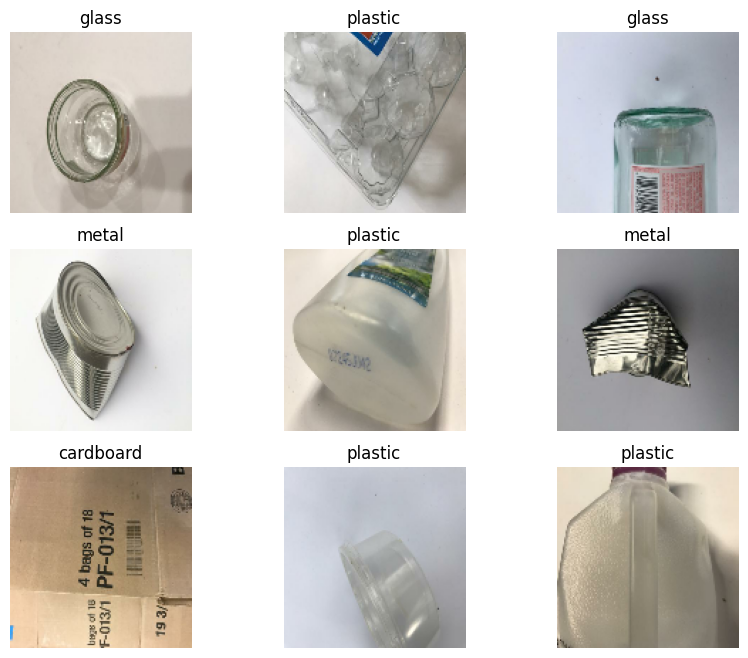

In [14]:

plt.figure(figsize=(10, 8))

for images, labels in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()


In [15]:

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(128,128,3)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(6, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,094 (28.20 MB)

 Trainable params: 7,393,094 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(128,128,3)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(6, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,094 (28.20 MB)

 Trainable params: 7,393,094 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=10
)

print("Model training completed!")


Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 56s 842ms/step - accuracy: 0.3066 - loss: 1.7788 - val_accuracy: 0.4178 - val_loss: 1.4208
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 80s 818ms/step - accuracy: 0.4777 - loss: 1.3469 - val_accuracy: 0.4634 - val_loss: 1.2875
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 53s 827ms/step - accuracy: 0.5500 - loss: 1.1721 - val_accuracy: 0.5921 - val_loss: 1.1523
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 81s 817ms/step - accuracy: 0.6048 - loss: 1.0408 - val_accuracy: 0.5802 - val_loss: 1.1118
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 82s 812ms/step - accuracy: 0.6518 - loss: 0.9311 - val_accuracy: 0.5901 - val_loss: 1.0733
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 54s 847ms/step - accuracy: 0.7250 - loss: 0.7632 - val_accuracy: 0.5921 - val_loss: 1.1366
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 80s 808ms/step - accuracy: 0.7789 - loss: 0.6300 - val_accuracy: 0.6040 - val_loss: 1.1029
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 54s 841ms/step - accuracy: 0.7982 - loss: 0.5658 - val_accu

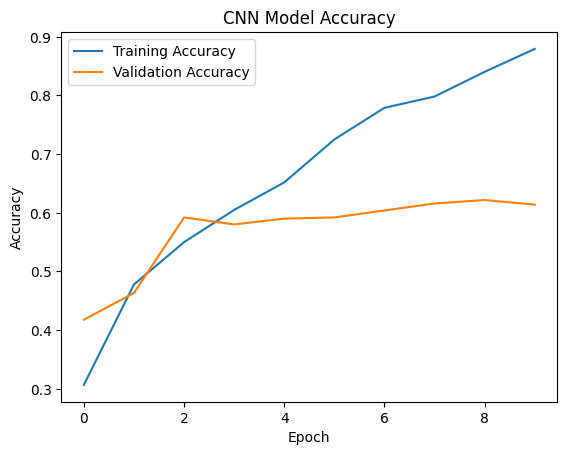

In [18]:

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


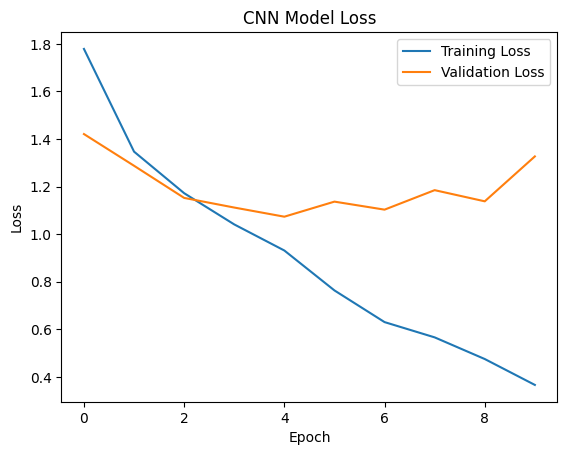

In [19]:

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [20]:

loss, accuracy = model.evaluate(test_data)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")


16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step - accuracy: 0.6139 - loss: 1.3267
Test Loss: 1.3267483711242676
Test Accuracy: 61.38613820075989 %


In [23]:

from google.colab import files
import os

# Check model
print("Model is ready!")

# Save model
model.save('/content/Garbage_Classification_Model.keras')

# Check saved file
print(os.path.exists('/content/Garbage_Classification_Model.keras'))

# Download model
files.download('/content/Garbage_Classification_Model.keras')

print("Model saved successfully!")


Model is ready!
True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved successfully!
